In [1]:
pip install pandas numpy matplotlib seaborn astropy requests tqdm pyarrow

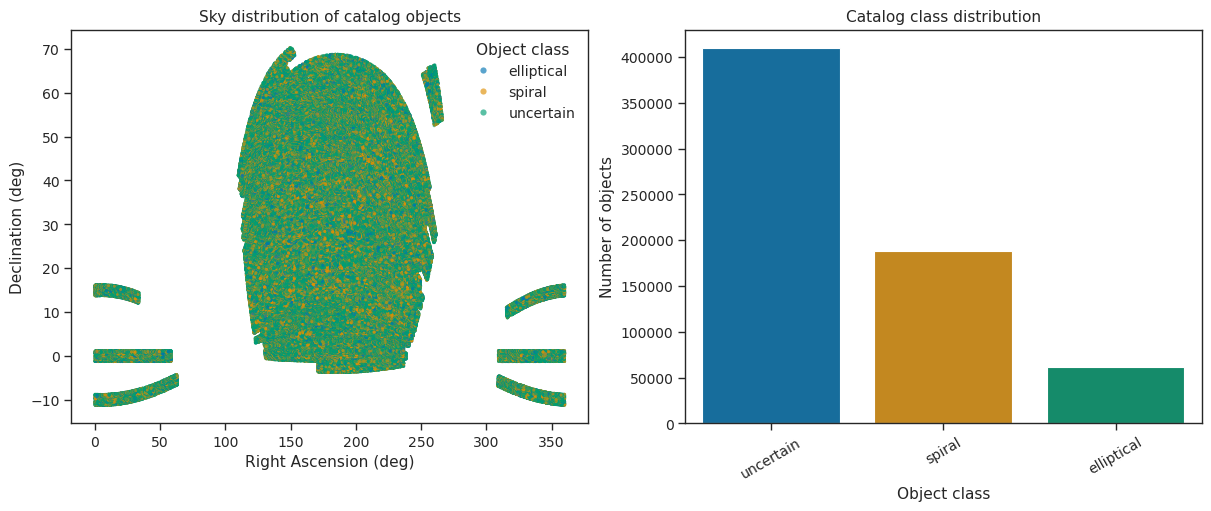

Number of catalog objects: 659272
class
uncertain     409446
spiral        188257
elliptical     61569
Name: count, dtype: int64


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load catalog
catalog = pd.read_csv("ZooSpecPhotoDR19_torradeflot.csv")

# Standardize column names
catalog.columns = catalog.columns.str.strip().str.lower()

# Define class dynamically from the Galaxy Zoo morphology columns
if "class" not in catalog.columns:
    # Determine class based on which column is set to 1 (or True)
    conds = [
        catalog["spiral"] == 1,
        catalog["elliptical"] == 1,
        catalog["uncertain"] == 1
    ]
    choices = ["spiral", "elliptical", "uncertain"]
    catalog["class"] = np.select(conds, choices, default="unknown")

# Check required columns
required = ["ra", "dec", "class"]
missing = [col for col in required if col not in catalog.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        f"Available columns: {list(catalog.columns)}"
    )

# Remove invalid coordinates and missing classes
catalog = catalog.dropna(subset=["ra", "dec", "class"]).copy()
catalog = catalog[
    catalog["ra"].between(0, 360)
    & catalog["dec"].between(-90, 90)
]

# 2. Publication-style settings
sns.set_theme(style="ticks", context="paper", font_scale=1.15)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), constrained_layout=True
)

# 3. Sky distribution
classes = sorted(catalog["class"].astype(str).unique())
palette = sns.color_palette("colorblind", n_colors=len(classes))

sns.scatterplot(
    data=catalog,
    x="ra",
    y="dec",
    hue="class",
    hue_order=classes,
    palette=palette,
    s=5,
    alpha=0.65,
    linewidth=0,
    rasterized=True,
    ax=axes[0]
)

axes[0].set_xlabel("Right Ascension (deg)")
axes[0].set_ylabel("Declination (deg)")
axes[0].set_title("Sky distribution of catalog objects")
axes[0].legend(
    title="Object class",
    markerscale=2,
    frameon=False
)

# 4. Redshift distribution, if available
if "redshift" in catalog.columns:
    redshift_data = catalog.dropna(subset=["redshift"]).copy()

    sns.histplot(
        data=redshift_data,
        x="redshift",
        hue="class",
        hue_order=classes,
        bins=50,
        element="step",
        stat="density",
        common_norm=False,
        palette=palette,
        alpha=0.25,
        ax=axes[1]
    )

    axes[1].set_xlabel("Redshift (z)")
    axes[1].set_ylabel("Probability density")
    axes[1].set_title("Redshift distribution by class")
else:
    counts = catalog["class"].astype(str).value_counts()

    sns.barplot(
        x=counts.index,
        y=counts.values,
        hue=counts.index,
        palette=palette,
        legend=False,
        ax=axes[1]
    )

    axes[1].set_xlabel("Object class")
    axes[1].set_ylabel("Number of objects")
    axes[1].set_title("Catalog class distribution")
    axes[1].tick_params(axis="x", rotation=30)

# 5. Save publication-quality figures
fig.savefig("catalog_figure.pdf", bbox_inches="tight")
fig.savefig("catalog_figure.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Number of catalog objects: {len(catalog)}")
print(catalog["class"].value_counts())

In [3]:
pip install pillow h5py

In [4]:

import io
import time
import h5py
import requests
import numpy as np
import pandas as pd

from PIL import Image
from concurrent.futures import ThreadPoolExecutor, as_completed
from requests.adapters import HTTPAdapter
from tqdm.auto import tqdm

# --------------------------------------------------
# Configuration
# --------------------------------------------------

CATALOG_FILE = "ZooSpecPhotoDR19_torradeflot.csv"
OUTPUT_FILE = "sdss_cutouts.h5"

IMAGE_SIZE = 64
SCALE = 0.4  # arcsec per pixel; verify for your science case
MAX_PER_CLASS = 1000
MAX_WORKERS = 4
TIMEOUT = 30
MAX_RETRIES = 3

BASE_URL = (
    "https://skyserver.sdss.org/dr19/"
    "SkyServerWS/ImgCutout/getjpeg"
)

# --------------------------------------------------
# Load and select a balanced subset
# --------------------------------------------------

df = pd.read_csv(CATALOG_FILE)
df.columns = df.columns.str.strip().str.lower()

# Define class dynamically from the Galaxy Zoo morphology columns
if "class" not in df.columns:
    conds = [
        df["spiral"] == 1,
        df["elliptical"] == 1,
        df["uncertain"] == 1
    ]
    choices = ["spiral", "elliptical", "uncertain"]
    df["class"] = np.select(conds, choices, default="unknown")

required = ["ra", "dec", "class"]
missing = set(required) - set(df.columns)

if missing:
    raise ValueError(f"Missing catalog columns: {missing}")

df = df.dropna(subset=["ra", "dec", "class"]).copy()
df = df[
    df["ra"].between(0, 360)
    & df["dec"].between(-90, 90)
]

# Remove classes with no usable label
df["class"] = df["class"].astype(str)

# Sample equally from each class
subset = (
    df.groupby("class", group_keys=False)
      .apply(
          lambda group: group.sample(
              n=min(len(group), MAX_PER_CLASS),
              random_state=42
          )
      )
      .reset_index(drop=True)
)

print("Selected objects:", len(subset))
print(subset["class"].value_counts())

# Encode labels as integers
class_names = sorted(subset["class"].unique())
class_to_id = {name: i for i, name in enumerate(class_names)}

# --------------------------------------------------
# Download one image
# --------------------------------------------------

def download_cutout(row):
    """Return (index, image, error). Image has shape H x W x 3."""

    params = {
        "ra": float(row.ra),
        "dec": float(row.dec),
        "scale": SCALE,
        "width": IMAGE_SIZE,
        "height": IMAGE_SIZE,
    }

    for attempt in range(MAX_RETRIES):
        try:
            # Each call creates its own session, avoiding
            # shared-session issues between worker threads.
            with requests.Session() as session:
                response = session.get(
                    BASE_URL,
                    params=params,
                    timeout=TIMEOUT
                )
                response.raise_for_status()

            image = Image.open(
                io.BytesIO(response.content)
            ).convert("RGB")

            image = image.resize(
                (IMAGE_SIZE, IMAGE_SIZE)
            )

            return row.Index, np.asarray(image), None

        except Exception as exc:
            if attempt == MAX_RETRIES - 1:
                return row.Index, None, str(exc)

            time.sleep(2 ** attempt)

    return row.Index, None, "Unknown error"


# --------------------------------------------------
# HDF5 output
# --------------------------------------------------

n = len(subset)

# Keep the output row associated with each catalog row.
subset = subset.reset_index(drop=True)

# Preserve the original metadata
subset["label_id"] = subset["class"].map(class_to_id)

# Compression reduces disk usage.
# Images are uint8 RGB arrays: N x 128 x 128 x 3.
with h5py.File(OUTPUT_FILE, "w") as h5:
    images = h5.create_dataset(
        "images",
        shape=(n, IMAGE_SIZE, IMAGE_SIZE, 3),
        dtype=np.uint8,
        chunks=(1, IMAGE_SIZE, IMAGE_SIZE, 3),
        compression="gzip",
        compression_opts=4
    )

    labels = h5.create_dataset(
        "labels", data=subset["label_id"].to_numpy()
    )
    ra_ds = h5.create_dataset(
        "ra", data=subset["ra"].to_numpy()
    )
    dec_ds = h5.create_dataset(
        "dec", data=subset["dec"].to_numpy()
    )

    # -1 indicates a failed download
    status = h5.create_dataset(
        "download_ok", data=np.zeros(n, dtype=np.uint8)
    )

    h5.attrs["image_size"] = IMAGE_SIZE
    h5.attrs["scale_arcsec_per_pixel"] = SCALE
    h5.attrs["class_names"] = np.array(
        class_names, dtype=h5py.string_dtype()
    )

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        futures = [
            pool.submit(download_cutout, row)
            for row in subset.itertuples(index=True)
        ]

        errors = []

        for future in tqdm(
            as_completed(futures),
            total=len(futures),
            desc="Downloading SDSS cutouts"
        ):
            idx, image, error = future.result()

            if error is not None:
                errors.append({
                    "index": idx,
                    "error": error
                })
                continue

            # Only the main thread writes to HDF5.
            images[idx] = image
            status[idx] = 1

print("Saved dataset:", OUTPUT_FILE)

# Save metadata and download errors for reproducibility
subset.to_csv("cutout_metadata.csv", index=False)
pd.DataFrame(errors).to_csv("download_errors.csv", index=False)

print("Successful downloads:", int(status.sum()) if False else
      "See download_ok in the HDF5 file")
print("Failed downloads:", len(errors))
print("Class mapping:", class_to_id)


Selected objects: 3000
class
elliptical    1000
spiral        1000
uncertain     1000
Name: count, dtype: int64


/tmp/ipykernel_13275/2234088025.py:67: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


Saved dataset: sdss_cutouts.h5
Successful downloads: See download_ok in the HDF5 file
Failed downloads: 0
Class mapping: {'elliptical': 0, 'spiral': 1, 'uncertain': 2}


Successful images: 3000
Failed images: 0
Image dimensions: (3000, 64, 64, 3)


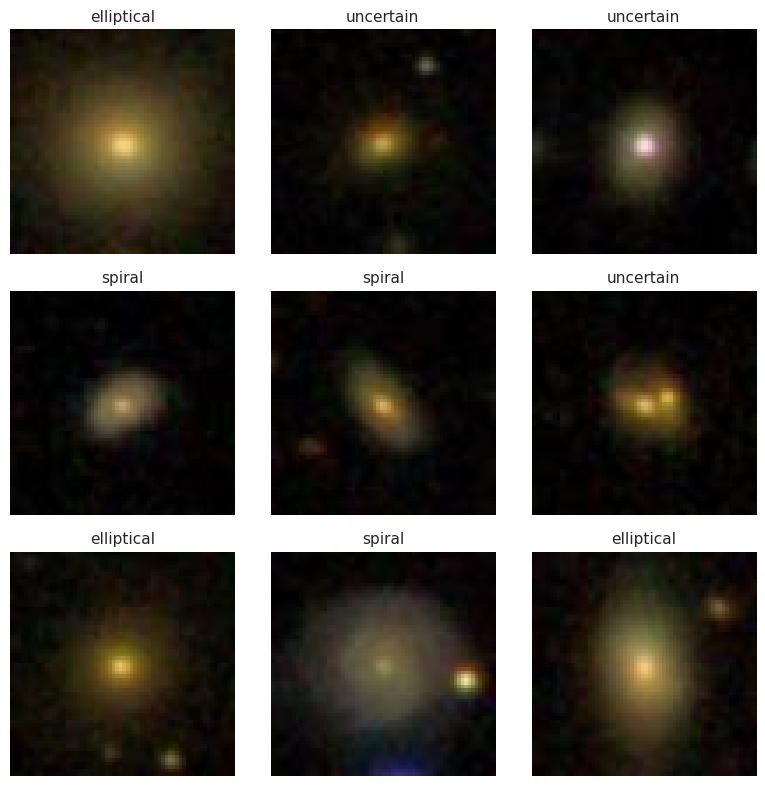

In [5]:

import h5py
import matplotlib.pyplot as plt
import numpy as np

with h5py.File("sdss_cutouts.h5", "r") as h5:
    images = h5["images"]
    labels = h5["labels"][:]
    ok = h5["download_ok"][:].astype(bool)

    class_names = [
        x.decode() if isinstance(x, bytes) else x
        for x in h5.attrs["class_names"]
    ]

    valid_indices = np.flatnonzero(ok)

    print("Successful images:", len(valid_indices))
    print("Failed images:", len(ok) - len(valid_indices))
    print("Image dimensions:", images.shape)

    if len(valid_indices):
        rng = np.random.default_rng(42)
        sample_indices = rng.choice(
            valid_indices,
            size=min(9, len(valid_indices)),
            replace=False
        )

        fig, axes = plt.subplots(3, 3, figsize=(8, 8))

        for ax, idx in zip(axes.flat, sample_indices):
            ax.imshow(images[idx])
            ax.set_title(class_names[labels[idx]])
            ax.axis("off")

        for ax in axes.flat[len(sample_indices):]:
            ax.axis("off")

        plt.tight_layout()
        plt.show()
